# Combining parallel calculations in a fixed order

Equal size groups use boundaries taken from an evenly spaced grid:

$$
b_j=\left\lceil\frac{jN}{K}\right\rceil,
\qquad j=0,1,\ldots,K.
$$

Here, $N$ is the number of indivisible tasks, $K$ is the number of groups after limiting it to at most $N$, $j$ labels a boundary, $b_j$ is that boundary, and $\lceil\cdot\rceil$ rounds upward.

Row,Boundary number,Equal size boundary,Increasing work boundary
,Int64,Int64,Int64
1,0,0,0
2,1,25,50
3,2,50,71
4,3,75,87
5,4,100,100


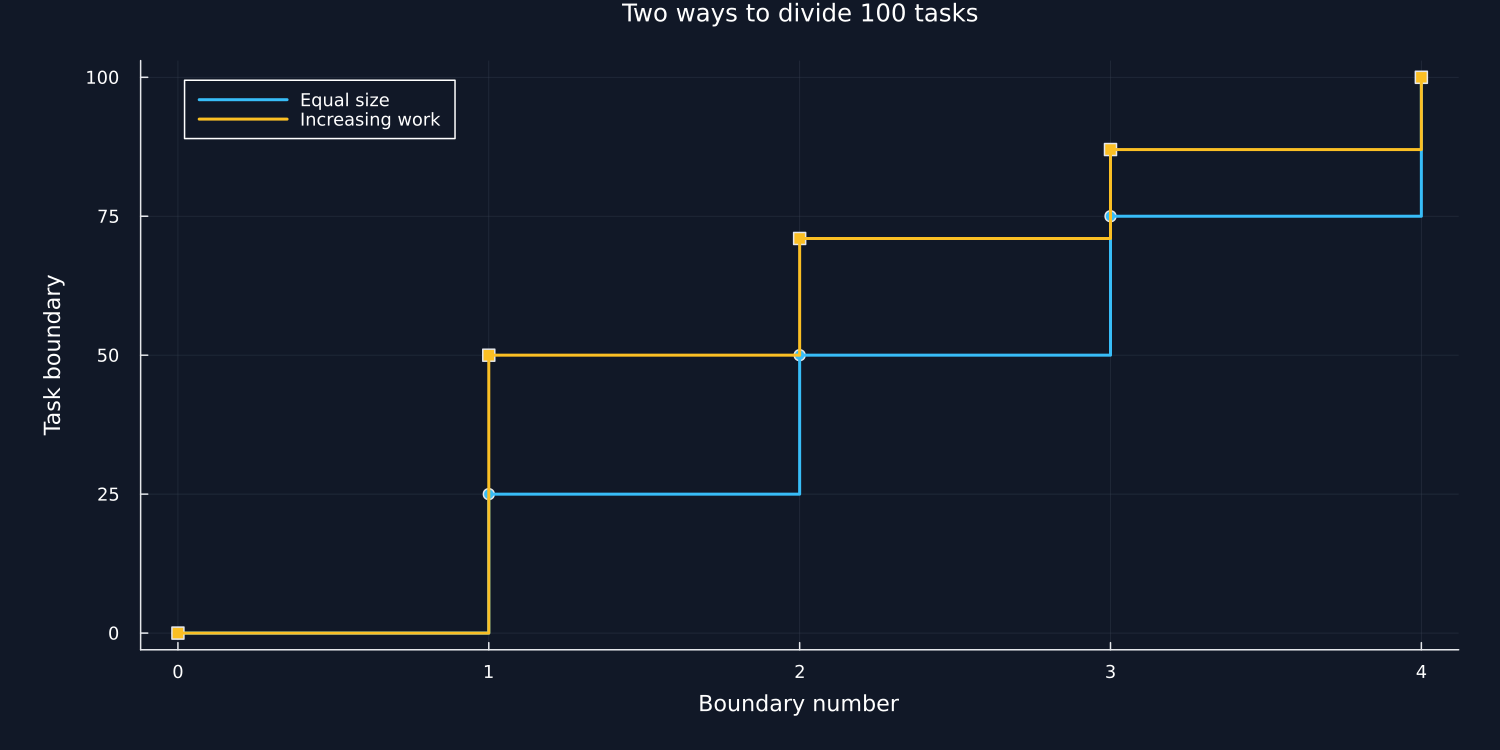

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("32_reproducible_research_study");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
using RiskLabAI.ParallelWork
using RiskLabAI.Components
using RiskLabAI.Utils
muted = "#94A3B8"
asset_names = selected_assets
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter30-"*replace(name,"_"=>"-"))
    return nothing
end
function binance_rows(limit=5000)
    full = load_binance()
    return DataFrame("Date Time"=>full.time[1:limit],"Price"=>full.close[1:limit],"Volume"=>full.volume[1:limit])
end
date_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")
function portfolio_weights(method,covariance,correlation)
    method=="Equal weight" && return fill(1/size(covariance,1),size(covariance,1))
    method=="Inverse variance" && return inverse_variance_weights(covariance)
    method=="Hierarchical risk parity" && return hrp(covariance,correlation)
    throw(KeyError(method))
end
function portfolio_record(method,weights,returns)
    daily = returns*weights
    wealth = cumprod(1 .+daily)
    drawdown = wealth./accumulate(max,wealth).-1
    concentration = sum(abs2,weights)
    return (Method=method,Observations=length(daily),annual_mean=mean(daily)*252,annual_volatility=std(daily)*sqrt(252),ratio=mean(daily)/std(daily)*sqrt(252),drawdown=minimum(drawdown),largest=maximum(weights),concentration=concentration,effective=1/concentration)
end
function portfolio_frame(records)
    frame = DataFrame(records)
    rename!(frame,["Method","Observations","Annual mean return","Annual volatility","Return to volatility","Maximum drawdown","Largest weight","Weight concentration","Effective holdings"])
    return sort(frame,["Annual volatility","Method"])
end
atom_count,group_count = 100,4
linear = linear_partitions(atom_count,group_count)
nested = nested_partitions(atom_count,group_count)
boundary_table = DataFrame("Boundary number"=>0:group_count,"Equal size boundary"=>linear,"Increasing work boundary"=>nested)
table(boundary_table,"partition_boundaries","Boundaries for 100 tasks and four groups.")
figure = plot(0:group_count,linear;seriestype=:steppost,marker=:circle,color=palette.cyan,label="Equal size",xlabel="Boundary number",ylabel="Task boundary",title="Two ways to divide 100 tasks",legend=:topleft,size=(1000,500))
plot!(figure,0:group_count,nested;seriestype=:steppost,marker=:square,color=palette.amber,label="Increasing work")
save_figure(figure,paths,"partition_boundaries")


## Balancing Increasing Work

When task $i$ has estimated work proportional to $i$, the next boundary follows the triangular work equation:

$$
b_j=\frac{-1+\sqrt{1+4\left(b_{j-1}^2+b_{j-1}+N(N+1)/K\right)}}{2}.
$$

Here, $i$ labels a task, its estimated work is proportional to $i$, $b_{j-1}$ is the preceding boundary, $b_j$ is the next boundary, $N(N+1)/2$ is total estimated work, and $K$ is the requested number of groups.

Row,Rule,Group,First task,Last task,Task count,Estimated work
,String,Int64,Int64,Int64,Int64,Int64
1,Equal size,1,1,25,25,325
2,Equal size,2,26,50,25,950
3,Equal size,3,51,75,25,1575
4,Equal size,4,76,100,25,2200
5,Increasing work,1,1,50,50,1275
6,Increasing work,2,51,71,21,1281
7,Increasing work,3,72,87,16,1272
8,Increasing work,4,88,100,13,1222


Row,Rule,Tasks,Mean group work,Work standard deviation,Least group work,Greatest group work
,String,Int64,Float64,Float64,Int64,Int64
1,Equal size,100,1262.5,806.872,325,2200
2,Increasing work,100,1262.5,27.258,1222,1281


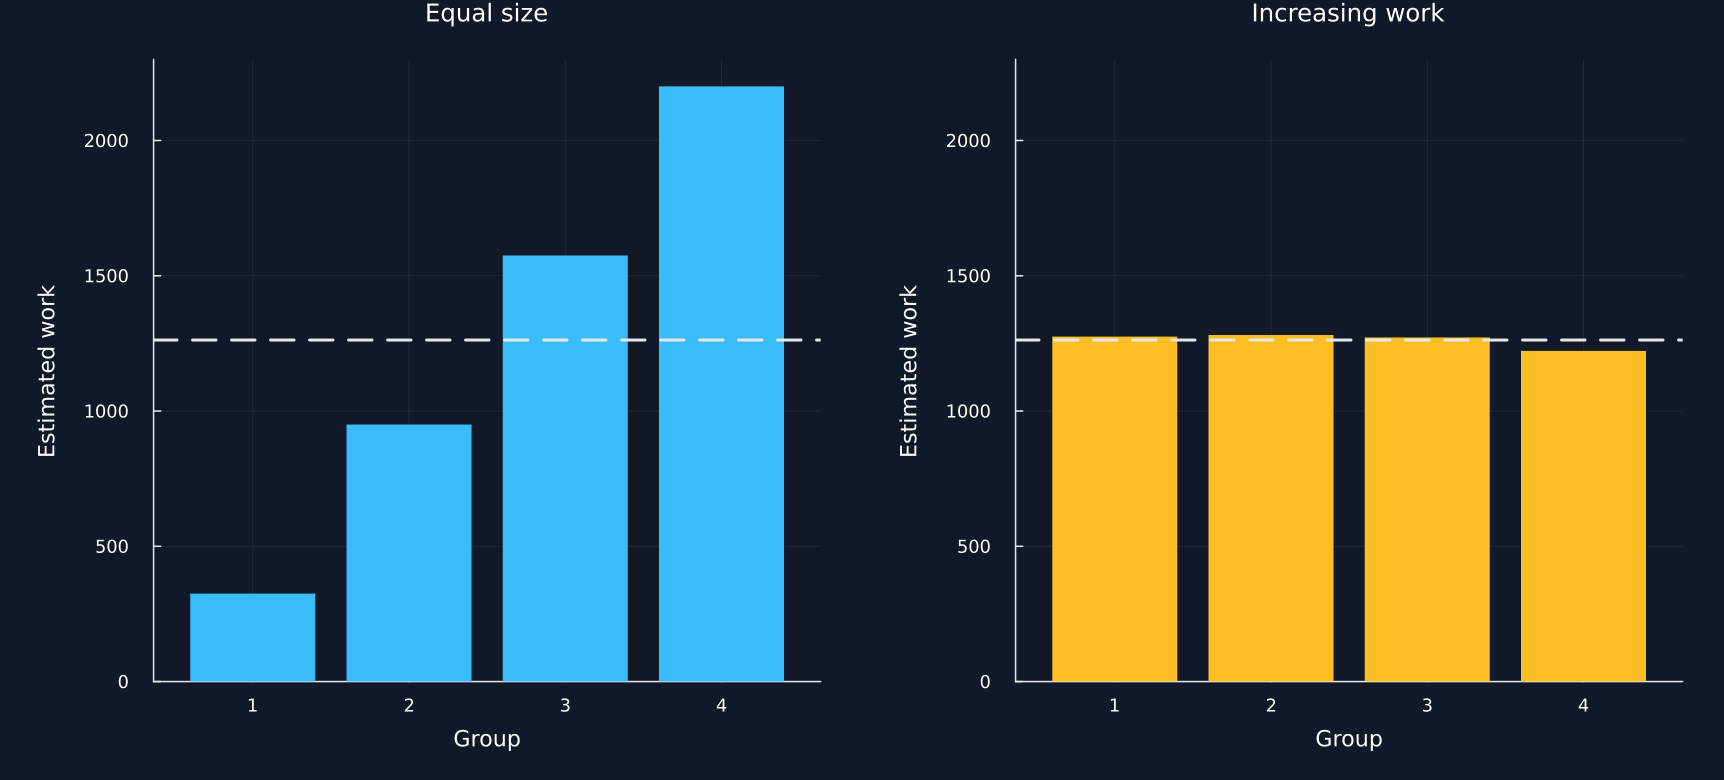

In [2]:
function group_rows(boundaries,rule)
    return [(Rule=rule,Group=i,first=boundaries[i]+1,last=boundaries[i+1],count=boundaries[i+1]-boundaries[i],work=sum((boundaries[i]+1):boundaries[i+1])) for i in 1:length(boundaries)-1]
end
workload_table = DataFrame(vcat(group_rows(linear,"Equal size"),group_rows(nested,"Increasing work")))
rename!(workload_table,["Rule","Group","First task","Last task","Task count","Estimated work"])
workload_summary = combine(groupby(workload_table,:Rule;sort=true),"Task count"=>sum=>"Tasks","Estimated work"=>mean=>"Mean group work","Estimated work"=>std=>"Work standard deviation","Estimated work"=>minimum=>"Least group work","Estimated work"=>maximum=>"Greatest group work")
table(workload_table,"partition_workloads","Task counts and estimated triangular work in each group.")
table(workload_summary,"partition_workload_summary","Dispersion of estimated work under the two grouping rules.")
panels = Plots.Plot[]
for (group,color) in zip(groupby(workload_table,:Rule;sort=false),[palette.cyan,palette.amber])
    figure = bar(group.Group,group[!,"Estimated work"];color,linealpha=0,legend=false,xlabel="Group",ylabel="Estimated work",title=first(group.Rule),ylims=(0,2300))
    hline!(figure,[mean(group[!,"Estimated work"])];color=palette.text,linestyle=:dash,label="")
    push!(panels,figure)
end
save_figure(plot(panels...;layout=(1,2),size=(1150,520)),paths,"partition_workload_balance")


## Preserving output order in parallel calculations

A keyed result can be placed in a stable order after all tasks finish:

$$
(y_{(1)},\ldots,y_{(N)})
=\operatorname{sort}_{k}\!\left\{(k_i,y_i):i=1,\ldots,N\right\}.
$$

Here, $i$ labels the order in which a result is received, $k_i$ is its stable key, $y_i$ is its value, and $y_{(1)},\ldots,y_{(N)}$ are the values after sorting by that key.

Row,Result rule,Position,Task,Squared value
,String,Int64,String,Float64
1,Submitted order,1,A,4.0
2,Submitted order,2,B,9.0
3,Submitted order,3,C,25.0
4,Submitted order,4,D,49.0
5,Completion order,1,B,9.0
6,Completion order,2,A,4.0
7,Completion order,3,D,49.0
8,Completion order,4,C,25.0
9,Key sorted order,1,A,4.0


Row,Calculation,Elapsed seconds,Tasks
,String,Float64,Int64
1,One task at a time,0.57227,4
2,Submitted order in parallel,0.731318,4
3,Completion order in parallel,0.38102,4


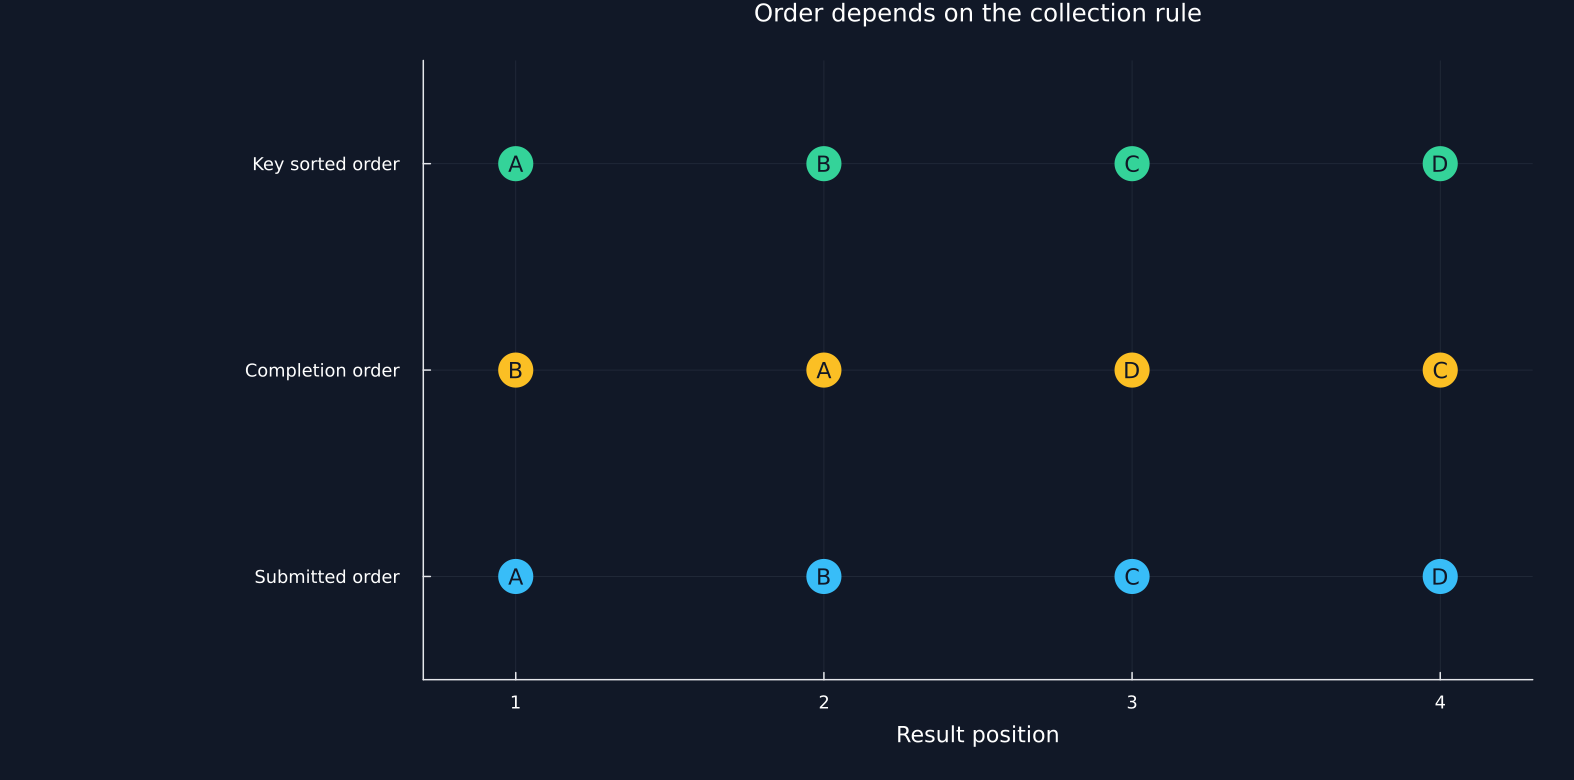

In [3]:
task_specs = [("A",.20,2.0),("B",.15,3.0),("C",.10,5.0),("D",.05,7.0)]
function timed_square(specification)
    key,delay,value = specification
    sleep(delay)
    return key,value^2
end
started = time_ns()
sequential_results = timed_square.(task_specs)
sequential_seconds = (time_ns()-started)/1e9
started = time_ns()
submitted_results = parallel_run(timed_square,task_specs;num_cpus=4)
submitted_seconds = (time_ns()-started)/1e9
started = time_ns()
completion_results = process_jobs([(func=(;specification)->timed_square(specification),specification=specification) for specification in task_specs];num_threads=4)
completion_seconds = (time_ns()-started)/1e9
key_order = Dict(specification[1]=>i for (i,specification) in enumerate(task_specs))
stable_results = sort(completion_results;by=item->key_order[item[1]])
order_table = DataFrame([(rule=rule,position=i,task=key,value=value) for (rule,values) in [("Submitted order",submitted_results),("Completion order",completion_results),("Key sorted order",stable_results)] for (i,(key,value)) in enumerate(values)])
rename!(order_table,["Result rule","Position","Task","Squared value"])
timing_table = DataFrame("Calculation"=>["One task at a time","Submitted order in parallel","Completion order in parallel"],"Elapsed seconds"=>[sequential_seconds,submitted_seconds,completion_seconds],"Tasks"=>fill(length(task_specs),3))
table(order_table,"result_order_comparison","The same keyed results under three presentation rules.")
table(timing_table,"small_task_timing","Measured time for four deliberately uneven tasks on this machine.")
order_names = ["Submitted order","Completion order","Key sorted order"]
figure = plot(;yticks=(0:2,order_names),xticks=1:4,xlabel="Result position",title="Order depends on the collection rule",legend=false,ylims=(-.5,2.5),xlims=(.7,4.3),left_margin=40Plots.mm,size=(1050,520))
for (index,color) in enumerate([palette.cyan,palette.amber,palette.green])
    rows = order_table[order_table[!,"Result rule"].==order_names[index],:]
    scatter!(figure,rows.Position,fill(index-1,4);color,markersize=13,markerstrokewidth=0)
    for row in eachrow(rows)
        annotate!(figure,row.Position,index-1,text(row.Task,10,palette.background))
    end
end
save_figure(figure,paths,"result_order_rules")


## Indexed Results

The indexed route combines group results and then orders the combined object by its index:

$$
Y=\operatorname{sortindex}\!\left(\operatorname{concat}(Y_1,\ldots,Y_K)\right).
$$

Here, $Y_j$ is the indexed result returned by group $j$, $K$ is the number of groups, $\operatorname{concat}$ joins those results, and $\operatorname{sortindex}$ restores increasing index order.

In [4]:
indexed_values = collect(0.0:11.0)
function reverse_partition(;molecule,values)
    chosen = reverse(molecule)
    return DataFrame("Observation"=>chosen,"Squared value"=>values[chosen.+1].^2)
end
indexed_table = parallel_indexed(reverse_partition,0:11;num_threads=1,mp_batches=3,index_column=:Observation,values=indexed_values)
source_rule_table = DataFrame("Released route"=>["General job collection","Named simultaneous calculation","Indexed table calculation"],"Observed rule"=>["Completion order","Submitted order","Increasing index"],"Direct check"=>["Source uses unordered collection","Uneven task check preserves submission","Reversed group output is sorted"])
table(indexed_table,"indexed_sort_check","Indexed results after group combination and final sorting.")
table(source_rule_table,"released_order_rules","Ordering rules for three released calculation routes.")


Row,Observation,Squared value
,Int64,Float64
1,0,0.0
2,1,1.0
3,2,4.0
4,3,9.0
5,4,16.0
6,5,25.0
7,6,36.0
8,7,49.0
9,8,64.0


Row,Released route,Observed rule,Direct check
,String,String,String
1,General job collection,Completion order,Source uses unordered collection
2,Named simultaneous calculation,Submitted order,Uneven task check preserves submission
3,Indexed table calculation,Increasing index,Reversed group output is sorted


## Timing public return calculations

The measured ratio of sequential time to simultaneous time is:

$$
S=\frac{T_{\mathrm{one}}}{T_{\mathrm{many}}}.
$$

Here, $T_{\mathrm{one}}$ is elapsed time when tasks are evaluated one at a time, $T_{\mathrm{many}}$ is elapsed time under the chosen simultaneous setting, and $S$ is a measured ratio for this task and machine rather than a universal guarantee.

Row,Field,Value
,String,Any
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Start date,2019-01-02
4,End date,2025-12-31
5,Complete observations,1760
6,Industries,16


Row,Industry,Observations,Annual mean return,Annual volatility,Mean rolling volatility,Greatest rolling volatility
,String,Int64,Float64,Float64,Float64,Float64
1,Agric,1760,0.189802,0.289434,0.274429,0.756894
2,Food,1760,0.0475793,0.167198,0.154077,0.481162
3,Soda,1760,0.12242,0.191464,0.173385,0.574366
4,Beer,1760,0.0632148,0.1975,0.175403,0.641972
5,Smoke,1760,0.172964,0.22345,0.206941,0.607746
6,Toys,1760,0.0856514,0.349448,0.332061,0.744766
7,Fun,1760,0.16612,0.306786,0.286154,0.654879
8,Books,1760,0.127718,0.246486,0.231317,0.650985
9,Hshld,1760,0.0816136,0.182269,0.164207,0.564325


Row,Repetition,One task at a time seconds,Simultaneous seconds,Measured ratio
,Int64,Float64,Float64,Float64
1,1,0.0983099,0.30739,0.319821
2,2,0.0022741,0.0102611,0.221623
3,3,0.0021579,0.0064001,0.337167
4,4,0.0022302,0.0012232,1.82325
5,5,0.0032185,0.0022923,1.40405


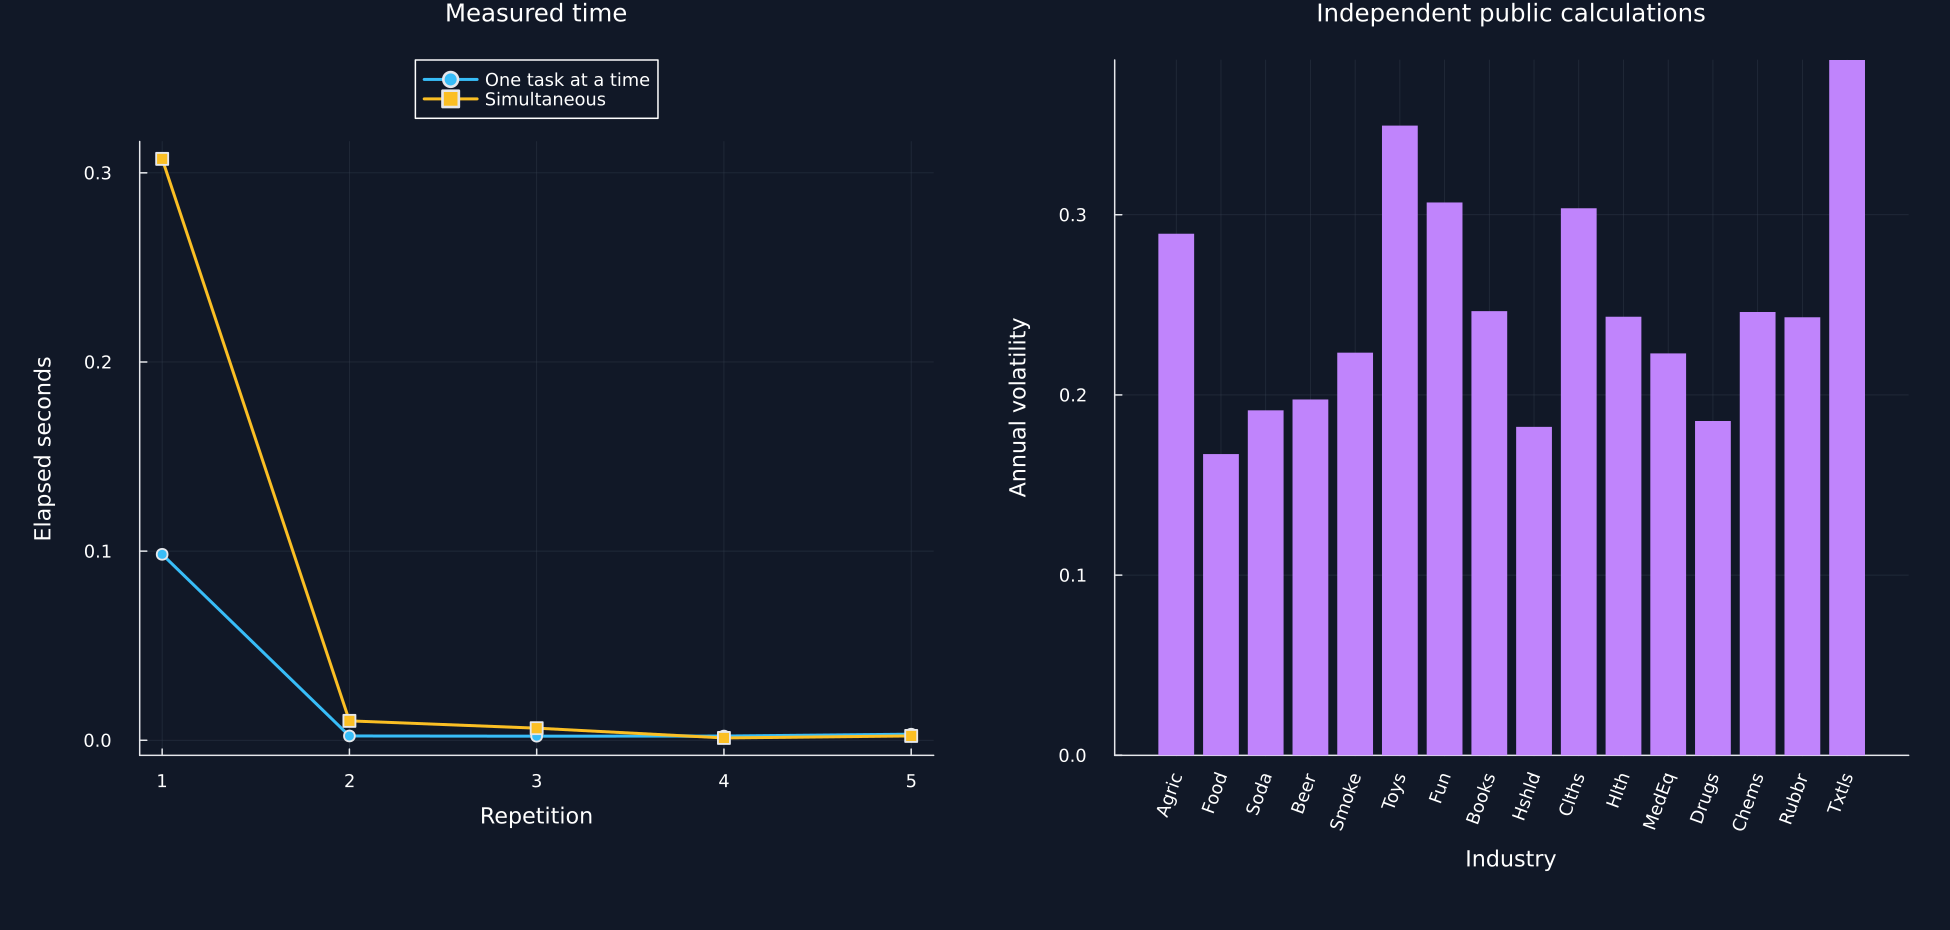

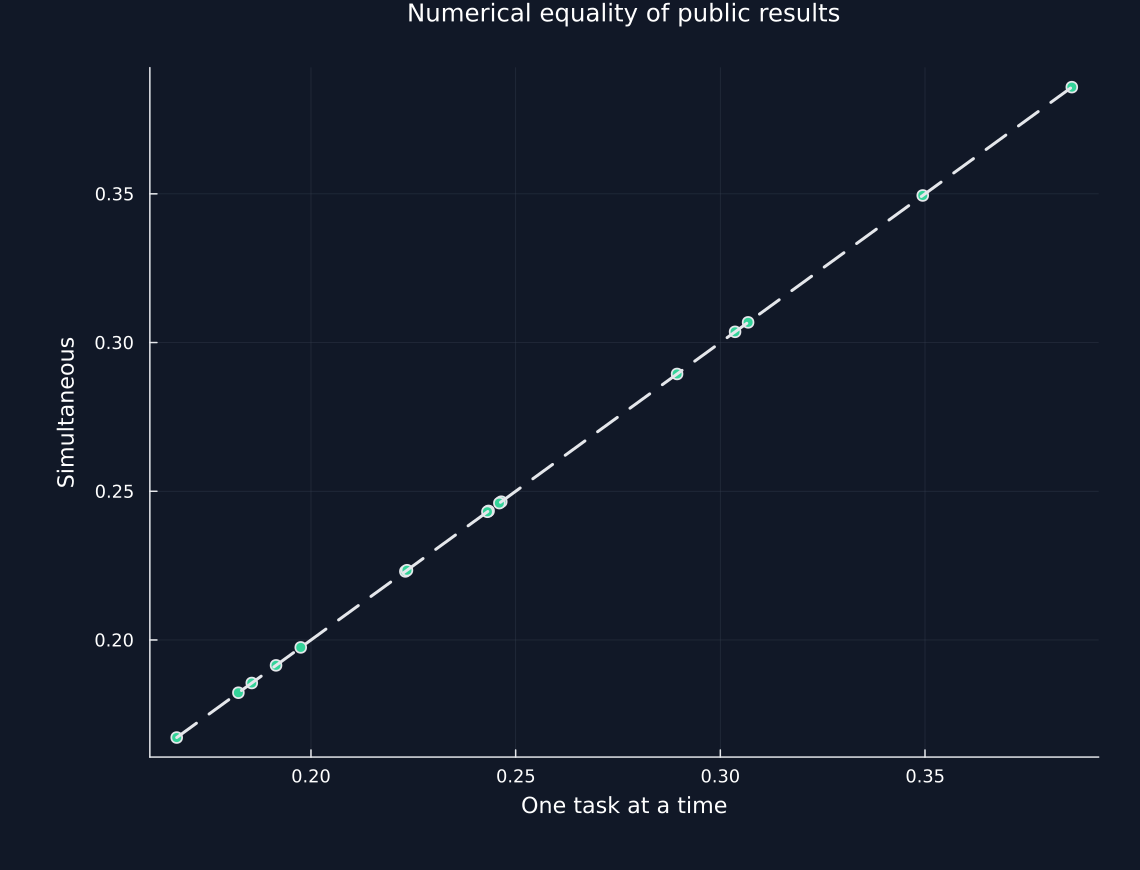

In [5]:
function asset_summary(index)
    values = public_sample[:,index]
    rolling = [std(values[(last-62):last])*sqrt(252) for last in 63:length(values)]
    return (Industry=asset_names[index],Observations=length(values),annual_mean=mean(values)*252,annual_volatility=std(values)*sqrt(252),mean_rolling=mean(rolling),greatest_rolling=maximum(rolling))
end
timing_rows = NamedTuple[]
sequential_public,parallel_public = nothing,nothing
for repetition in 1:5
    started = time_ns()
    sequential_public = asset_summary.(1:16)
    one_seconds = (time_ns()-started)/1e9
    started = time_ns()
    parallel_public = parallel_run(asset_summary,1:16;num_cpus=4)
    many_seconds = (time_ns()-started)/1e9
    push!(timing_rows,(Repetition=repetition,one=one_seconds,many=many_seconds,ratio=one_seconds/many_seconds))
end
public_summary = DataFrame(parallel_public)
rename!(public_summary,["Industry","Observations","Annual mean return","Annual volatility","Mean rolling volatility","Greatest rolling volatility"])
public_timing = DataFrame(timing_rows)
rename!(public_timing,["Repetition","One task at a time seconds","Simultaneous seconds","Measured ratio"])
public_provenance = DataFrame("Field"=>["Archive","Provider","Start date","End date","Complete observations","Industries"],"Value"=>Any["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library",string(first(dates)),string(last(dates)),length(dates),16])
table(public_provenance,"parallel_data_provenance","Public return source used for the calculation timing check.")
table(public_summary,"public_return_calculations","Public return summaries calculated separately for sixteen industries.")
table(public_timing,"public_calculation_timing","Five measured calculation times under the two execution settings.")
p1 = plot(1:5,public_timing[!,2];color=palette.cyan,marker=:circle,label="One task at a time",xlabel="Repetition",ylabel="Elapsed seconds",title="Measured time",legend=:outertop)
plot!(p1,1:5,public_timing[!,3];color=palette.amber,marker=:square,label="Simultaneous")
p2 = bar(1:16,public_summary[!,"Annual volatility"];color=violet,linealpha=0,legend=false,xticks=(1:16,asset_names),xrotation=70,xlabel="Industry",ylabel="Annual volatility",title="Independent public calculations",bottom_margin=17Plots.mm)
save_figure(plot(p1,p2;layout=(1,2),size=(1300,620)),paths,"public_calculation_timing_and_results")
sequential_frame = sort(DataFrame(sequential_public),:Industry)
parallel_frame = sort(DataFrame(parallel_public),:Industry)
bounds = extrema(sequential_frame.annual_volatility)
figure = scatter(sequential_frame.annual_volatility,parallel_frame.annual_volatility;color=palette.green,label="",xlabel="One task at a time",ylabel="Simultaneous",title="Numerical equality of public results",size=(760,580))
plot!(figure,collect(bounds),collect(bounds);color=palette.text,linestyle=:dash,label="")
save_figure(figure,paths,"public_calculation_equality")


## Tests

In [6]:
@assert linear==[0,25,50,75,100]
@assert nested==[0,50,71,87,100]
@assert all(combine(groupby(workload_table,:Rule),"Task count"=>sum)[!,2].==atom_count)
@assert workload_summary[workload_summary.Rule.=="Increasing work","Work standard deviation"][1]<workload_summary[workload_summary.Rule.=="Equal size","Work standard deviation"][1]
@assert submitted_results==sequential_results
@assert stable_results==sequential_results
@assert sort(completion_results)==sort(sequential_results)
@assert issorted(indexed_table.Observation)
@assert indexed_table[!,"Squared value"]==Float64.(0:11).^2
native_parallel_source = read(joinpath(dirname(pathof(RiskLabAI)),"ParallelWork.jl"),String)
@assert occursin("ordered::Bool = false",native_parallel_source)
@assert occursin("sort!(combined, index_column)",native_parallel_source)
@assert sequential_frame==parallel_frame
@assert nrow(public_summary)==16
@assert nrow(public_timing)==5
@assert all(isfinite,Matrix(public_timing))
@assert all(public_timing[!,2].>0) && all(public_timing[!,3].>0)
@assert all(isfinite,timing_table[!,"Elapsed seconds"])
@assert Threads.nthreads()==2
display(DataFrame("Test"=>["Equal size boundaries","Increasing work boundaries","Every task included","Increasing work balance","Submitted order","Key sorted order","Same keyed results","Indexed sorting","Completion collection source","Public numerical equality","Repeated timing"],"Passed"=>fill(true,11)))


Row,Test,Passed
,String,Bool
1,Equal size boundaries,true
2,Increasing work boundaries,true
3,Every task included,true
4,Increasing work balance,true
5,Submitted order,true
6,Key sorted order,true
7,Same keyed results,true
8,Indexed sorting,true
9,Completion collection source,true
